# DenseNet-121 + SE



In [ ]:
!pip -q install torch torchvision kagglehub pandas scikit-learn seaborn tqdm opencv-python-headless matplotlib

In [ ]:
SAVE_TO_DRIVE = True
DRIVE_FOLDER = "alzheimer-densenet-se"
REBUILD_SPLIT = True

In [ ]:
import json
import random
import re
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import (
    accuracy_score, auc, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_recall_curve, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import models
from torchvision.models import DenseNet121_Weights
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

KAGGLE_DATASET = "ninadaithal/imagesoasis"
DISPLAY_CLASS_NAMES = ["Mild Dementia", "Moderate Dementia", "Non Demented", "Very mild Dementia"]
CLASS_NAMES = ["MildDementia", "ModerateDementia", "NonDemented", "VeryMildDementia"]
CLASS_TO_IDX = {n: i for i, n in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {i: n for n, i in CLASS_TO_IDX.items()}
DISPLAY_TO_CANONICAL = {
    "Mild Dementia": "MildDementia", "Moderate Dementia": "ModerateDementia",
    "Non Demented": "NonDemented", "Very mild Dementia": "VeryMildDementia",
    "Very Mild Dementia": "VeryMildDementia",
}
LABEL_ALIASES = {
    "milddementia": "MildDementia", "moderatedementia": "ModerateDementia",
    "nondemented": "NonDemented", "verymilddementia": "VeryMildDementia",
}
SUBJECT_RX = [re.compile(r"(OAS\d+_\d+_MR\d+)", re.I), re.compile(r"(OAS\d+_\d+)", re.I)]


@dataclass
class Config:
    data_root: str = ""
    split_csv: str = "artifacts/team_split_train_test.csv"
    output_dir: str = "artifacts"
    img_size: int = 224
    batch_size: int = 48
    num_workers: int = 0
    max_epochs: int = 16
    lr: float = 1e-3
    finetune_lr: float = 3e-5
    weight_decay: float = 1e-4
    patience: int = 4
    seed: int = 42
    use_pretrained: bool = True
    use_class_weights: bool = True
    use_weighted_sampler: bool = True
    label_smoothing: float = 0.0
    grad_clip: float = 1.0
    rebuild_split: bool = True
    test_ratio: float = 0.20
    monitor_frac: float = 0.10
    freeze_epochs: int = 4


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def download_dataset():
    import kagglehub
    root = Path(kagglehub.dataset_download(KAGGLE_DATASET))
    if _has_classes(root):
        return str(root)
    for p in sorted(root.rglob("*")):
        if p.is_dir() and _has_classes(p):
            return str(p)
    raise FileNotFoundError(f"Class folders not found under {root}")


def _has_classes(path):
    return sum(1 for d in path.iterdir() if d.is_dir() and _label_folder(d.name)) >= 3


def _label_folder(name):
    if name in DISPLAY_TO_CANONICAL:
        return DISPLAY_TO_CANONICAL[name]
    return LABEL_ALIASES.get(re.sub(r"[^a-z0-9]", "", name.lower()))


def display_name(label_idx):
    inv = {v: k for k, v in DISPLAY_TO_CANONICAL.items()}
    return inv.get(IDX_TO_CLASS[label_idx], str(label_idx))


def extract_subject_id(path):
    for rx in SUBJECT_RX:
        m = rx.search(path)
        if m:
            parts = m.group(1).upper().split("_")
            if len(parts) >= 3 and parts[2].startswith("MR"):
                return "_".join(parts[:2])
            return "_".join(parts[:2])
    return f"UNK_{Path(path).stem[:12]}"


def discover_images(data_root):
    rows = []
    for fp in data_root.rglob("*"):
        if fp.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp"}:
            continue
        label, display = None, None
        for parent in fp.parents:
            if parent == data_root:
                break
            lab = _label_folder(parent.name)
            if lab:
                label, display = lab, parent.name
                break
        if not label:
            continue
        rows.append({
            "filepath": str(fp.relative_to(data_root)).replace("\\", "/"),
            "label_name": label, "label_display": display,
            "label": CLASS_TO_IDX[label], "subject_id": extract_subject_id(str(fp)),
        })
    return pd.DataFrame(rows)


def build_train_test_split(df, seed, test_ratio):
    sub = df.groupby("subject_id").agg(label=("label", "first")).reset_index()
    tr, te = train_test_split(sub.subject_id, test_size=test_ratio, random_state=seed, stratify=sub.label)
    mp = {s: "train" for s in tr}
    mp.update({s: "test" for s in te})
    out = df.copy()
    out["split"] = out.subject_id.map(mp)
    return out


def audit_leakage(df):
    per = {s: set(df.loc[df.split == s, "subject_id"]) for s in df.split.unique()}
    keys = list(per)
    ov = {}
    for i, a in enumerate(keys):
        for b in keys[i + 1:]:
            ov[f"{a}_vs_{b}"] = len(per[a] & per[b])
    return {"overlap": ov, "leakage_free": all(v == 0 for v in ov.values())}


def prepare_split(cfg, full_df=None):
    root = Path(cfg.data_root or download_dataset())
    cfg.data_root = str(root)
    full_df = full_df if full_df is not None else discover_images(root)
    Path(cfg.output_dir).mkdir(parents=True, exist_ok=True)
    p = Path(cfg.split_csv)
    if p.exists() and not cfg.rebuild_split:
        df = pd.read_csv(p)
    else:
        df = build_train_test_split(full_df, cfg.seed, cfg.test_ratio)
        df.to_csv(p, index=False)
    leak = audit_leakage(df)
    assert leak["leakage_free"], leak
    return df, full_df, leak


def get_transforms(size, train):
    mean, std = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
    if train:
        return T.Compose([
            T.Resize((size, size)), T.RandomHorizontalFlip(0.5),
            T.RandomAffine(0, translate=(0.05, 0.05), scale=(0.92, 1.08)),
            T.ColorJitter(0.1, 0.1), T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize(mean, std),
        ])
    return T.Compose([
        T.Resize((size, size)), T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize(mean, std),
    ])


class MRIDataset(Dataset):
    def __init__(self, df, root, tfm=None):
        self.df = df.reset_index(drop=True)
        self.root = Path(root)
        self.tfm = tfm

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = Image.open(self.root / r.filepath).convert("RGB")
        if self.tfm:
            img = self.tfm(img)
        return img, int(r.label)


class SELayer(nn.Module):
    def __init__(self, ch, r=16):
        super().__init__()
        h = max(ch // r, 8)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(nn.Linear(ch, h, False), nn.ReLU(True), nn.Linear(h, ch, False), nn.Sigmoid())

    def forward(self, x):
        b, c, _, _ = x.shape
        w = self.fc(self.pool(x).view(b, c)).view(b, c, 1, 1)
        return x * w


class SEDenseNet121(nn.Module):
    def __init__(self, n_classes=4, pretrained=True):
        super().__init__()
        w = DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
        base = models.densenet121(weights=w)
        self.features = base.features
        self.classifier = nn.Linear(base.classifier.in_features, n_classes)
        self.se1, self.se2, self.se3, self.se4 = SELayer(256), SELayer(512), SELayer(1024), SELayer(1024)
        self._act = None
        self._grad = None

    def forward(self, x):
        x = self.features.pool0(self.features.relu0(self.features.norm0(self.features.conv0(x))))
        x = self.se1(self.features.denseblock1(x))
        x = self.features.transition1(x)
        x = self.se2(self.features.denseblock2(x))
        x = self.features.transition2(x)
        x = self.se3(self.features.denseblock3(x))
        x = self.features.transition3(x)
        x = self.se4(self.features.denseblock4(x))
        x = F.relu(self.features.norm5(x), inplace=True)
        return self.classifier(torch.flatten(F.adaptive_avg_pool2d(x, 1), 1))

    def gradcam_hooks(self):
        self.se4.register_forward_hook(lambda _m, _i, o: setattr(self, "_act", o))
        self.se4.register_full_backward_hook(lambda _m, _gi, go: setattr(self, "_grad", go[0]))

In [ ]:
def make_loaders(df, cfg, root):
    train = df[df.split == "train"]
    test = df[df.split == "test"]
    sub = train.groupby("subject_id").agg(label=("label", "first")).reset_index()
    fit_id, mon_id = train_test_split(sub.subject_id, test_size=cfg.monitor_frac, random_state=cfg.seed, stratify=sub.label)
    fit_df = train[train.subject_id.isin(fit_id)]
    mon_df = train[train.subject_id.isin(mon_id)]
    kw = dict(num_workers=cfg.num_workers, pin_memory=True)
    if cfg.use_weighted_sampler:
        c = fit_df.label.value_counts().sort_index()
        samp = WeightedRandomSampler(fit_df.label.map(1.0 / c).values, len(fit_df), True)
        tl = DataLoader(MRIDataset(fit_df, root, get_transforms(cfg.img_size, True)), cfg.batch_size, sampler=samp, shuffle=False, **kw)
    else:
        tl = DataLoader(MRIDataset(fit_df, root, get_transforms(cfg.img_size, True)), cfg.batch_size, shuffle=True, **kw)
    ml = DataLoader(MRIDataset(mon_df, root, get_transforms(cfg.img_size, False)), cfg.batch_size, shuffle=False, **kw)
    test_l = DataLoader(MRIDataset(test, root, get_transforms(cfg.img_size, False)), cfg.batch_size, shuffle=False, **kw)
    return tl, ml, test_l, fit_df


def class_weights(train_df):
    c = train_df.label.value_counts().sort_index()
    w = torch.ones(4)
    for i, n in c.items():
        w[int(i)] = len(train_df) / (4 * n)
    return w


@torch.no_grad()
def predict_probs(model, loader, device):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        p = model(x.to(device)).softmax(1).cpu().numpy()
        ys.extend(y.numpy().tolist())
        ps.append(p)
    return np.array(ys), np.concatenate(ps, axis=0)


def evaluate(model, loader, device):
    y, p = predict_probs(model, loader, device)
    pred = p.argmax(1)
    return {
        "y_true": y, "y_prob": p, "y_pred": pred,
        "accuracy": accuracy_score(y, pred),
        "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
        "report": classification_report(y, pred, target_names=DISPLAY_CLASS_NAMES, zero_division=0),
        "confusion": confusion_matrix(y, pred),
    }


def monitor_f1(model, loader, device, max_batches=35):
    model.eval()
    ys, preds = [], []
    for i, (x, y) in enumerate(loader):
        if i >= max_batches:
            break
        preds.extend(model(x.to(device)).argmax(1).cpu().tolist())
        ys.extend(y.numpy().tolist())
    return f1_score(ys, preds, average="macro", zero_division=0)


def plot_roc_pr(y_true, y_prob, out_dir):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    y_bin = label_binarize(y_true, classes=list(range(4)))

    fig, ax = plt.subplots(figsize=(7, 6))
    for i, name in enumerate(DISPLAY_CLASS_NAMES):
        if (y_true == i).sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
        ax.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.2f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC — test (one-vs-rest)")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(out_dir / "roc_curves_test.png", dpi=150)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(7, 6))
    for i, name in enumerate(DISPLAY_CLASS_NAMES):
        if (y_true == i).sum() == 0:
            continue
        prec, rec, _ = precision_recall_curve(y_bin[:, i], y_prob[:, i])
        ap = average_precision_score(y_bin[:, i], y_prob[:, i])
        ax.plot(rec, prec, label=f"{name} (AP={ap:.2f})")
    ax.set(xlabel="Recall", ylabel="Precision", title="Precision–Recall — test")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(out_dir / "pr_curves_test.png", dpi=150)
    plt.close(fig)


def save_confusion(cm, path):
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=DISPLAY_CLASS_NAMES, yticklabels=DISPLAY_CLASS_NAMES, ax=ax)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def train_epoch(model, loader, opt, crit, device, scaler, clip):
    model.train()
    total = 0.0
    for x, y in tqdm(loader, leave=False):
        x, y = x.to(device), y.to(device)
        opt.zero_grad(set_to_none=True)
        if scaler:
            with autocast():
                loss = crit(model(x), y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            scaler.step(opt)
            scaler.update()
        else:
            loss = crit(model(x), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
        total += loss.item() * len(x)
    return total / len(loader.dataset)


def fit(cfg, full_df=None):
    set_seed(cfg.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    df, full_df, leak = prepare_split(cfg, full_df)
    root = Path(cfg.data_root)
    out = Path(cfg.output_dir)
    tl, ml, test_l, fit_df = make_loaders(df, cfg, root)

    model = SEDenseNet121(4, cfg.use_pretrained).to(device)
    model.gradcam_hooks()
    cw = class_weights(fit_df).to(device) if cfg.use_class_weights else None
    crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=cfg.label_smoothing)
    scaler = GradScaler() if device.type == "cuda" else None
    ckpt = out / "best_densenet_se.pt"
    best, wait = -1.0, 0

    for p in model.features.parameters():
        p.requires_grad = False
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=cfg.lr, weight_decay=cfg.weight_decay)
    for ep in range(1, cfg.freeze_epochs + 1):
        loss = train_epoch(model, tl, opt, crit, device, scaler, cfg.grad_clip)
        f1 = monitor_f1(model, ml, device)
        print(f"frozen {ep}: loss={loss:.4f} monitor_f1={f1:.4f}")
        if f1 > best:
            best, wait = f1, 0
            torch.save({"model": model.state_dict()}, ckpt)
        else:
            wait += 1

    for m in (model.features.denseblock3, model.features.transition3, model.features.denseblock4, model.features.norm5):
        for p in m.parameters():
            p.requires_grad = True
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=cfg.finetune_lr, weight_decay=cfg.weight_decay)
    wait = 0
    for ep in range(cfg.freeze_epochs + 1, cfg.max_epochs + 1):
        loss = train_epoch(model, tl, opt, crit, device, scaler, cfg.grad_clip)
        f1 = monitor_f1(model, ml, device)
        print(f"finetune {ep}: loss={loss:.4f} monitor_f1={f1:.4f}")
        if f1 > best:
            best, wait = f1, 0
            torch.save({"model": model.state_dict()}, ckpt)
        else:
            wait += 1
            if wait >= cfg.patience:
                break

    model.load_state_dict(torch.load(ckpt, map_location=device, weights_only=False)["model"])
    metrics = evaluate(model, test_l, device)
    print(metrics["report"])
    save_confusion(metrics["confusion"], out / "confusion_matrix_test.png")
    plot_roc_pr(metrics["y_true"], metrics["y_prob"], out)
    (out / "test_classification_report.txt").write_text(metrics["report"])
    json.dump({"accuracy": metrics["accuracy"], "macro_f1": metrics["macro_f1"], "confusion": metrics["confusion"].tolist()},
              open(out / "test_metrics.json", "w"), indent=2)
    return model, metrics, df, device, leak


def gradcam(model, tensor, cls, device):
    model.eval()
    model.zero_grad(set_to_none=True)
    model(tensor.unsqueeze(0).to(device))[0, cls].backward()
    w = model._grad.mean((2, 3), keepdim=True)
    cam = F.relu((w * model._act).sum(1, keepdim=True))
    cam = F.interpolate(cam, tensor.shape[-2:], mode="bilinear", align_corners=False)
    cam = cam.squeeze().detach().cpu().numpy()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)


def save_gradcam(model, df, data_root, device, out_dir, n=1):
    import cv2
    out = Path(out_dir) / "gradcam"
    out.mkdir(parents=True, exist_ok=True)
    tfm = get_transforms(224, False)
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    test = df[df.split == "test"]
    for _, row in test.groupby("label").head(n).iterrows():
        x = tfm(Image.open(Path(data_root) / row.filepath).convert("RGB")).to(device)
        pred = model(x.unsqueeze(0)).argmax(1).item()
        cam = gradcam(model, x, pred, device)
        img = (x.cpu() * std + mean).permute(1, 2, 0).numpy().clip(0, 1)
        heat = cv2.cvtColor(cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB) / 255.0
        fig, ax = plt.subplots(1, 3, figsize=(11, 4))
        ax[0].imshow(img)
        ax[0].set_title(row.label_display)
        ax[0].axis("off")
        ax[1].imshow(cam, cmap="jet")
        ax[1].set_title("Grad-CAM")
        ax[1].axis("off")
        ax[2].imshow(img)
        ax[2].imshow(heat, alpha=0.45)
        ax[2].set_title(f"Pred: {display_name(pred)}")
        ax[2].axis("off")
        safe = re.sub(r"[^a-zA-Z0-9]+", "_", row.label_display)
        fig.savefig(out / f"gradcam_{safe}.png", dpi=150, bbox_inches="tight")
        plt.close(fig)

In [ ]:
set_seed(42)
cfg = Config(data_root=download_dataset(), output_dir="artifacts", rebuild_split=REBUILD_SPLIT, test_ratio=0.20)
full_df = discover_images(Path(cfg.data_root))
print("Images:", len(full_df), "Patients:", full_df.subject_id.nunique())
print(full_df.groupby("label_display").size())

model, metrics, df, device, leak = fit(cfg, full_df)
save_gradcam(model, df, cfg.data_root, device, cfg.output_dir)
print("accuracy", round(metrics["accuracy"], 4), "macro_f1", round(metrics["macro_f1"], 4))

Using Colab cache for faster access to the 'imagesoasis' dataset.
Images: 86437 Patients: 347
label_display
Mild Dementia          5002
Moderate Dementia       488
Non Demented          67222
Very mild Dementia    13725
dtype: int64
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 144MB/s]
/tmp/ipykernel_897/847876271.py:139: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler() if device.type == "cuda" else None


  0%|          | 0/1292 [00:00<?, ?it/s]

/tmp/ipykernel_897/847876271.py:111: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


frozen 1: loss=0.1344 monitor_f1=0.1653


...

/tmp/ipykernel_897/847876271.py:111: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


finetune 14: loss=0.0009 monitor_f1=0.3110


  0%|          | 0/1292 [00:00<?, ?it/s]

/tmp/ipykernel_897/847876271.py:111: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


finetune 15: loss=0.0012 monitor_f1=0.3015
                    precision    recall  f1-score   support

     Mild Dementia       0.26      0.20      0.22       915
 Moderate Dementia       0.00      0.00      0.00         0
      Non Demented       0.88      0.86      0.87     14152
Very mild Dementia       0.38      0.43      0.40      2745

          accuracy                           0.76     17812
         macro avg       0.38      0.37      0.37     17812
      weighted avg       0.77      0.76      0.76     17812

accuracy 0.7626 macro_f1 0.3738


roc_curves_test.png


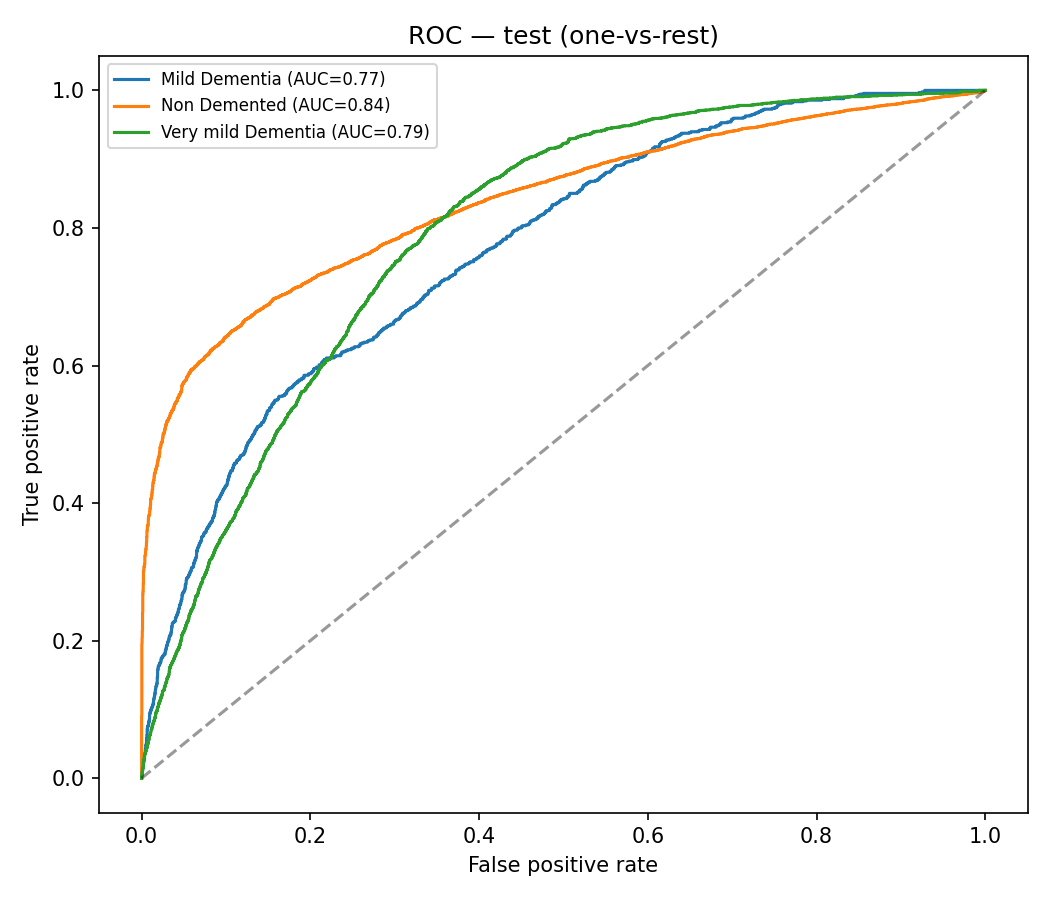

pr_curves_test.png


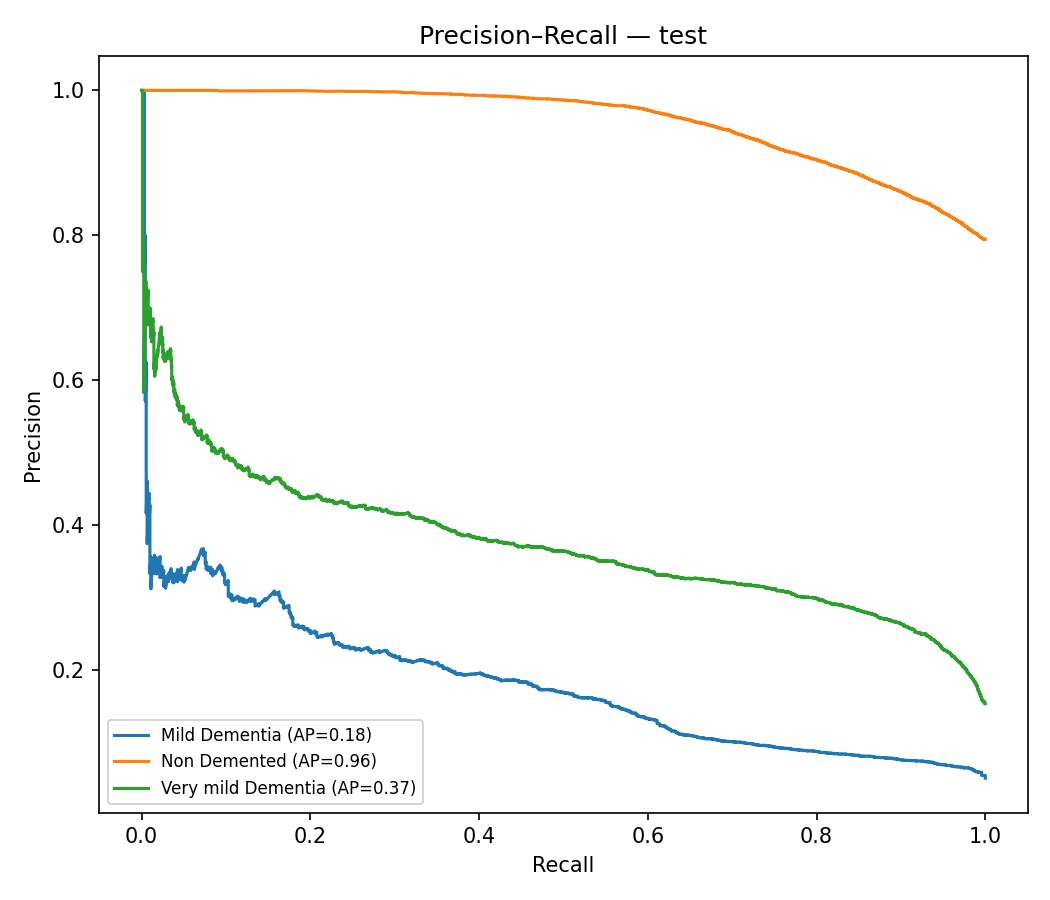

confusion_matrix_test.png


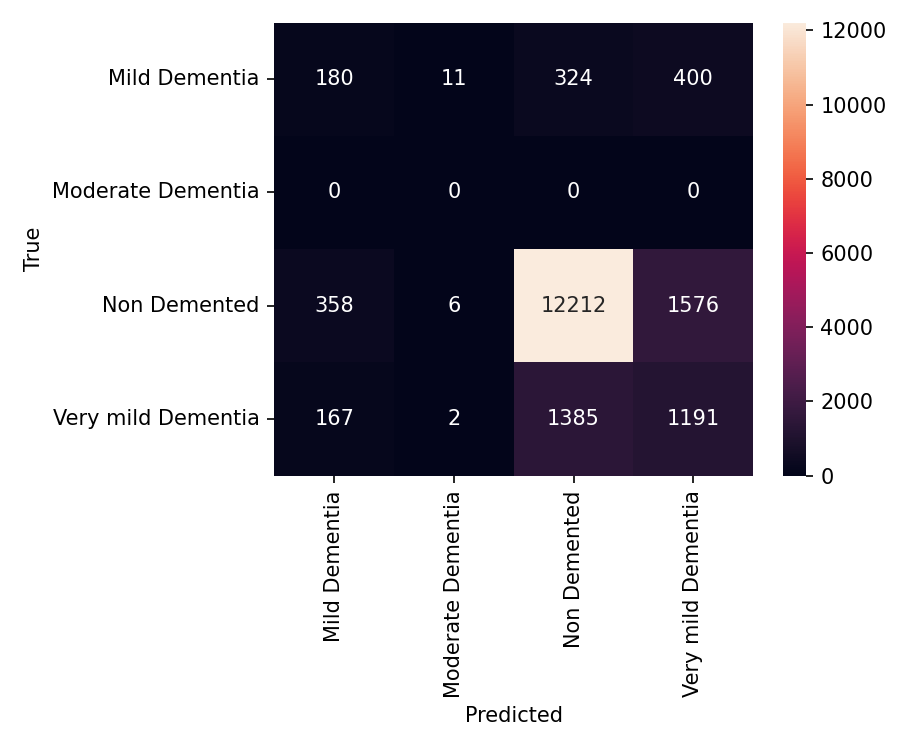

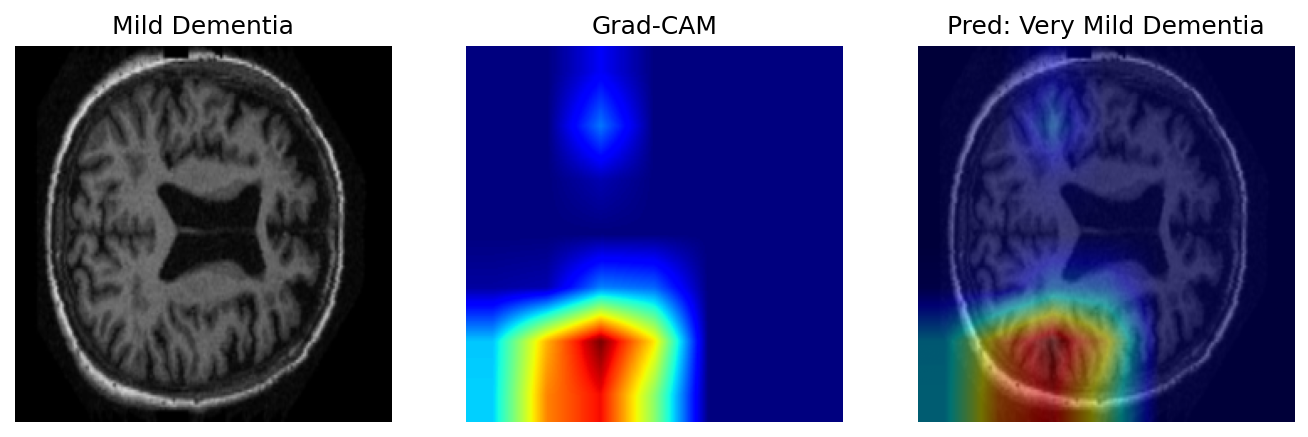

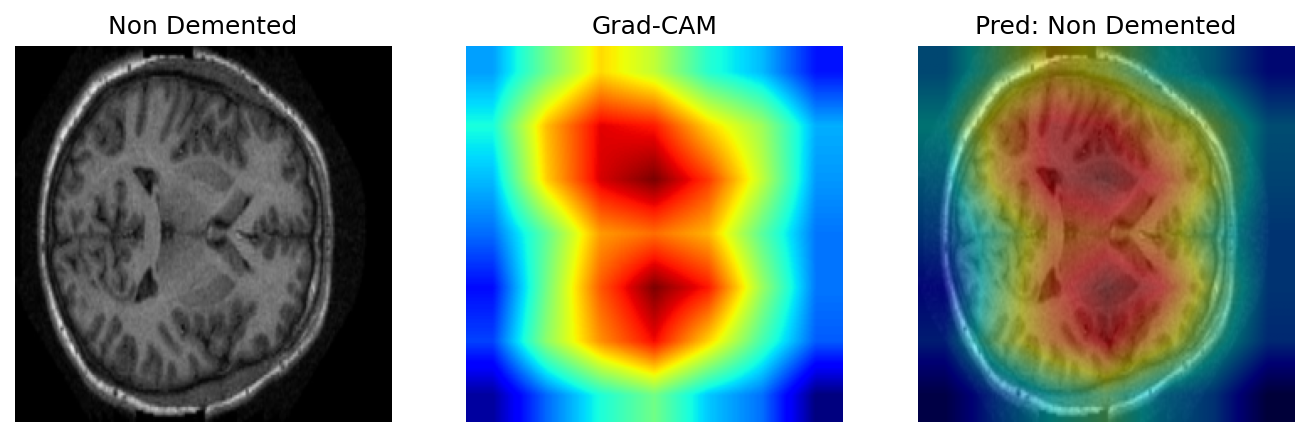

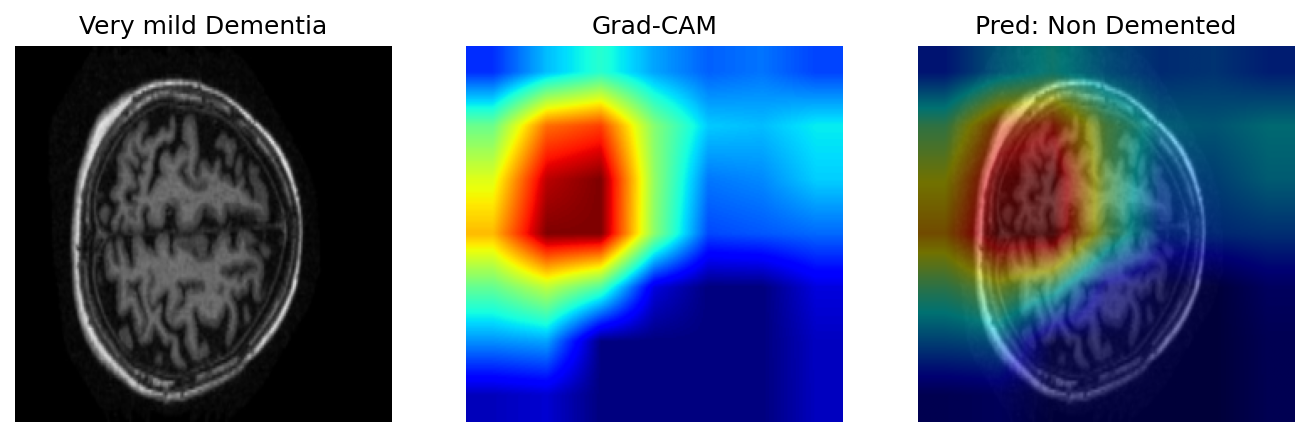

In [ ]:
from IPython.display import Image as IPImage, display

for name in ["roc_curves_test.png", "pr_curves_test.png", "confusion_matrix_test.png"]:
    p = Path("artifacts") / name
    if p.exists():
        print(name)
        display(IPImage(filename=str(p)))

for p in sorted((Path("artifacts") / "gradcam").glob("*.png")):
    display(IPImage(filename=str(p)))

In [ ]:
from datetime import datetime
import shutil

RUN = datetime.now().strftime("%Y%m%d_%H%M%S")
ART = Path("artifacts")

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    dest = Path("/content/drive/MyDrive") / DRIVE_FOLDER / RUN
    dest.mkdir(parents=True, exist_ok=True)
    for f in ART.rglob("*"):
        if f.is_file():
            t = dest / f.relative_to(ART)
            t.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(f, t)
    print("Drive:", dest)

from google.colab import files
z = f"/content/densenet_results_{RUN}"
shutil.make_archive(z, "zip", ART)
files.download(z + ".zip")

Mounted at /content/drive
Drive: /content/drive/MyDrive/alzheimer-densenet-se/20260525_202746


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>